# Tracking biofilm movement and breakup
**Time: 1–2 hours. AI assistance is allowed.** Complete the TODOs, check the images,
and explain your results. Save this notebook alongside `biofilm.zip`, `colony_masks.npz`,
and `breakup_scores.csv`. Requirements: numpy, pandas, tifffile, matplotlib, Pillow.

The masks already preserve colony IDs. Your job is to measure territory-centroid movement
and analyze the supplied teaching breakup scores. Scores range from 0 to 100; higher indicates
greater fragmentation according to the supplied indicator. They are not percentages of released
cells or biomass. Their generation is outside this exercise.

These are selected annotations on Chou et al. (2026), Supplementary Video 1.
Not every visible colony has a supplied mask. Use the listed colony IDs only.
Measurements use pixels and frame numbers because physical calibration is unverified.
Centroid movement can also reflect changing territory shape.

Submit ONLY this completed, saved notebook (.ipynb), with its outputs retained. Include both
results tables, the mask overlay, trajectory animation, movement/breakup figure, and a 100–150 word
interpretation. The final cell embeds your tables for grading. No separate CSVs or GIF are required.
Automatic measurements: 70 points.
Loading/alignment/completeness: 10 points. Visualization: 10 points. Interpretation: 10 points.


In [1]:
# Colab: upload biofilm.zip, colony_masks.npz and breakup_scores.csv next to this notebook
# (Files panel), or mount Drive and put them in MyDrive/biofilm. Locally nothing is needed.
import importlib.util, subprocess, sys
if importlib.util.find_spec('tifffile') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'tifffile'], check=True)

from pathlib import Path
import io, zipfile
import numpy as np
import pandas as pd
import tifffile
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Image as NotebookImage
DATA = Path.cwd()
if not (DATA / 'biofilm.zip').exists() and Path('/content/drive/MyDrive/biofilm/biofilm.zip').exists():
    DATA = Path('/content/drive/MyDrive/biofilm')  # optional Drive location
OUTPUT = DATA / 'submission'
OUTPUT.mkdir(exist_ok=True)
with zipfile.ZipFile(DATA / 'biofilm.zip') as archive:
    names = sorted(archive.namelist())
print('Images:', names[:3], '...')

Images: ['biofilm/frame_000.tif', 'biofilm/frame_001.tif', 'biofilm/frame_002.tif'] ...


## 1. Load and display an image
The first image is loaded for you. Complete the second example. TIFFs are 2D arrays:
the first index is row (y), the second is column (x).


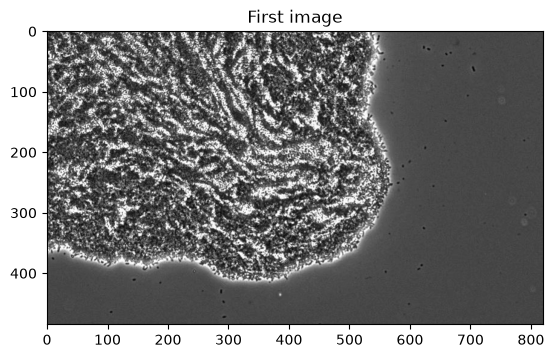

Image shape (rows y, columns x): (485, 820) uint8


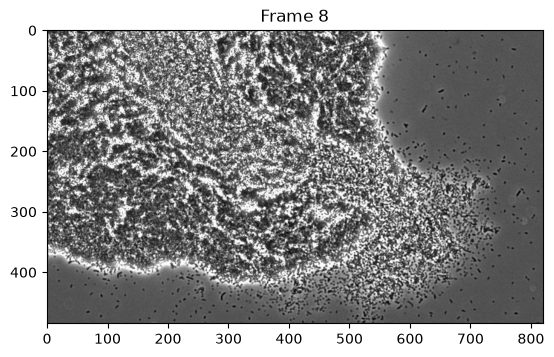

In [2]:
with zipfile.ZipFile(DATA / 'biofilm.zip') as archive:
    first_image = tifffile.imread(io.BytesIO(archive.read(names[0])))
plt.imshow(first_image, cmap='gray'); plt.title('First image'); plt.show()

frame_to_show = 8
with zipfile.ZipFile(DATA / 'biofilm.zip') as archive:
    another_image = tifffile.imread(io.BytesIO(archive.read(f'biofilm/frame_{frame_to_show:03d}.tif')))
print('Image shape (rows y, columns x):', another_image.shape, another_image.dtype)
plt.imshow(another_image, cmap='gray'); plt.title(f'Frame {frame_to_show}'); plt.show()

## 2. Load and overlay the masks
Image–mask pairs have already been matched by the organizers. `image_filenames` gives
their exact order. Load the mask array, then overlay the mask for `frame_to_show`.
Confirm that boundaries follow the matching raw image. Unknown calibration fields contain NaN.


Available fields: ['masks', 'image_filenames', 'image_sha256', 'colony_ids', 'frame_indices', 'source_frame_indices', 'frame_times_minutes', 'pixel_size_um', 'mask_kind', 'axes', 'dataset_version', 'source_credit']
Frames, rows, cols: (17, 485, 820) | colonies: [10, 13, 17, 20, 27, 28, 33, 41]


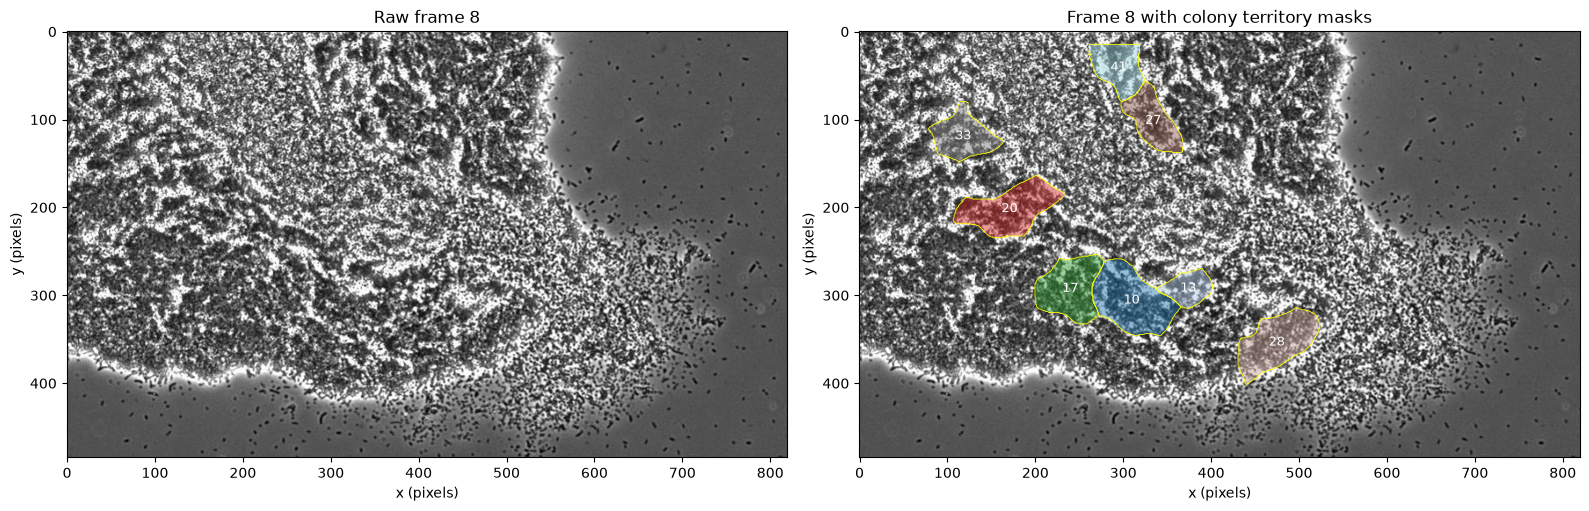

In [3]:
with np.load(DATA / 'colony_masks.npz', allow_pickle=False) as archive:
    print('Available fields:', archive.files)
    filenames = archive['image_filenames'].copy()
    colony_ids = archive['colony_ids'].copy()
    masks = archive['masks'].copy()
assert masks is not None, 'Load masks before continuing'
with zipfile.ZipFile(DATA / 'biofilm.zip') as archive:
    images = np.stack([tifffile.imread(io.BytesIO(archive.read('biofilm/' + str(name)))) for name in filenames])
assert images.shape == masks.shape
print('Frames, rows, cols:', masks.shape, '| colonies:', colony_ids.tolist())

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].imshow(images[frame_to_show], cmap='gray'); axes[0].set_title(f'Raw frame {frame_to_show}')
axes[1].imshow(images[frame_to_show], cmap='gray')
overlay = np.ma.masked_equal(masks[frame_to_show], 0)
axes[1].imshow(overlay, cmap='tab20', alpha=0.45, interpolation='nearest')
for ident in colony_ids:
    axes[1].contour(masks[frame_to_show] == ident, levels=[0.5], colors='yellow', linewidths=0.6)
    yy, xx = np.nonzero(masks[frame_to_show] == ident)
    if len(xx):
        axes[1].text(xx.mean(), yy.mean(), str(int(ident)), color='white', fontsize=9, ha='center', va='center')
axes[1].set_title(f'Frame {frame_to_show} with colony territory masks')
for ax in axes:
    ax.set(xlabel='x (pixels)', ylabel='y (pixels)')
fig.tight_layout(); plt.show()

## 3. Measure a colony centroid
Here is a complete example. x is column, y is row. Use the territory mask, not brightness.
Repeat for a second colony and draw its centroid on the image.


10 306.52864188163886 305.8645675265554


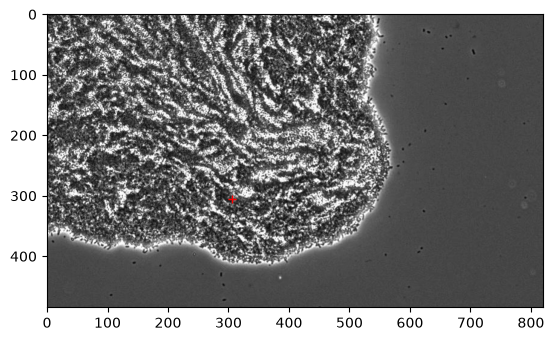

13 364.57218309859155 293.35079225352115


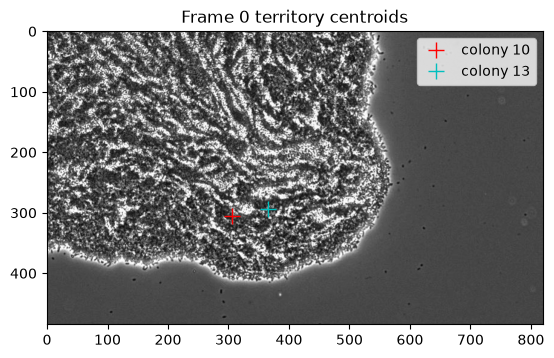

In [4]:
example_id = int(colony_ids[0])
yy, xx = np.nonzero(masks[0] == example_id)
example_x, example_y = xx.mean(), yy.mean()
print(example_id, example_x, example_y)
plt.imshow(images[0], cmap='gray')
plt.plot(example_x, example_y, 'r+')
plt.show()

second_id = int(colony_ids[1])
yy2, xx2 = np.nonzero(masks[0] == second_id)
second_x, second_y = xx2.mean(), yy2.mean()
print(second_id, second_x, second_y)
plt.imshow(images[0], cmap='gray')
plt.plot(example_x, example_y, 'r+', markersize=12, label=f'colony {example_id}')
plt.plot(second_x, second_y, 'c+', markersize=12, label=f'colony {second_id}')
plt.legend(); plt.title('Frame 0 territory centroids'); plt.show()

## 4. Follow every colony
Complete `measure_centroids`. Return one row for every colony and every frame, including
absent observations as NaN coordinates. Columns: `colony_id, frame, centroid_x_px, centroid_y_px`.
Hint: start from the example above and add loops. Do not replace missing coordinates with zero.


In [5]:
def measure_centroids(masks, colony_ids):
    rows = []
    for ident in colony_ids:
        for frame in range(len(masks)):
            yy, xx = np.nonzero(masks[frame] == ident)
            if len(xx):
                x, y = xx.mean(), yy.mean()
            else:
                x, y = np.nan, np.nan  # absent observation: keep NaN, never 0
            rows.append({'colony_id': int(ident), 'frame': frame,
                         'centroid_x_px': float(x), 'centroid_y_px': float(y)})
    return pd.DataFrame(rows, columns=['colony_id', 'frame', 'centroid_x_px', 'centroid_y_px'])

centroids = measure_centroids(masks, colony_ids)
assert len(centroids) == len(masks) * len(colony_ids)
example = centroids[(centroids.colony_id == example_id) & (centroids.frame == 0)].iloc[0]
assert np.isclose(example.centroid_x_px, example_x)
assert np.isclose(example.centroid_y_px, example_y)
print('Absent observations:', int(centroids.centroid_x_px.isna().sum()))
centroids.head()

Absent observations: 0


,colony_id,frame,centroid_x_px,centroid_y_px
0,10,0,306.528642,305.864568
1,10,1,306.562030,308.085472
2,10,2,306.089985,307.379317
3,10,3,305.715588,306.419784
4,10,4,306.434558,304.853055


## 5. Calculate movement
Displacement is Euclidean distance from the first observed centroid. Step distance uses
consecutive observed frames only. Cumulative distance sums valid steps. The first observed
frame has step distance 0 if it is frame 0; otherwise its step is NaN. On absent frames,
all movement entries are NaN. After a gap, resume the existing cumulative total without
adding a step across the gap.

Example: centroids (0,0), (3,4), (3,0) give displacements 0,5,3 and cumulative distances 0,5,9.
Return the original columns plus `displacement_px, step_distance_px, cumulative_distance_px`.


In [6]:
def calculate_movement(centroids):
    out = []
    for ident, track in centroids.groupby('colony_id', sort=True):
        track = track.sort_values('frame').copy()
        disp, step, cum = [], [], []
        start = None      # first observed centroid
        prev = None       # (frame, x, y) of the previous observed frame
        total = 0.0
        for frame, x, y in zip(track.frame, track.centroid_x_px, track.centroid_y_px):
            if not (np.isfinite(x) and np.isfinite(y)):
                disp.append(np.nan); step.append(np.nan); cum.append(np.nan)
                continue
            if start is None:
                start = (x, y)
                s = 0.0 if frame == 0 else np.nan
            elif prev[0] == frame - 1:
                s = float(np.hypot(x - prev[1], y - prev[2]))
            else:
                s = np.nan  # gap: no step across missing frames
            if np.isfinite(s):
                total += s
            disp.append(float(np.hypot(x - start[0], y - start[1])))
            step.append(s)
            cum.append(total)
            prev = (frame, x, y)
        track['displacement_px'] = disp
        track['step_distance_px'] = step
        track['cumulative_distance_px'] = cum
        out.append(track)
    return pd.concat(out, ignore_index=True)

# Worked example: (0,0), (3,4), (3,0) -> displacement 0,5,3; cumulative 0,5,9.
_check = calculate_movement(pd.DataFrame({'colony_id': 1, 'frame': [0, 1, 2],
                                          'centroid_x_px': [0., 3., 3.], 'centroid_y_px': [0., 4., 0.]}))
assert np.allclose(_check.displacement_px, [0, 5, 3]) and np.allclose(_check.cumulative_distance_px, [0, 5, 9])
# Gap rules: first seen at frame 1 -> step NaN; absent frame -> all NaN; resume the total without a step across the gap.
_gap = calculate_movement(pd.DataFrame({'colony_id': 1, 'frame': [0, 1, 2, 3, 4],
                                        'centroid_x_px': [np.nan, 0., 3., np.nan, 3.],
                                        'centroid_y_px': [np.nan, 0., 4., np.nan, 0.]}))
assert np.allclose(_gap.cumulative_distance_px, [np.nan, 0, 5, np.nan, 5], equal_nan=True)
assert np.allclose(_gap.step_distance_px, [np.nan, np.nan, 5, np.nan, np.nan], equal_nan=True)
assert np.allclose(_gap.displacement_px, [np.nan, 0, 5, np.nan, 3], equal_nan=True)

movement = calculate_movement(centroids)
movement.head()

,colony_id,frame,centroid_x_px,centroid_y_px,displacement_px,step_distance_px,cumulative_distance_px
0,10,0,306.528642,305.864568,0.000000,0.000000,0.000000
1,10,1,306.562030,308.085472,2.221155,2.221155,2.221155
2,10,2,306.089985,307.379317,1.576986,0.849400,3.070556
3,10,3,305.715588,306.419784,0.984542,1.029989,4.100545
4,10,4,306.434558,304.853055,1.015878,1.723820,5.824365


## 6. Analyze supplied breakup scores
Load the CSV using the example below. For each colony, calculate `breakup_change` relative to
its first finite score. Identify the first frame with score >= THRESHOLD, including frame 0.
No crossing stays NaN. Scores can decrease. Use the supplied rounded scores exactly.
Return the scores with a `breakup_change` column and a table of `colony_id, first_threshold_frame`.


In [7]:
THRESHOLD = 40.0
scores = pd.read_csv(DATA / 'breakup_scores.csv')
display(scores.head())

def analyze_breakup(scores, threshold):
    scored, crossings = [], []
    for ident, track in scores.groupby('colony_id', sort=True):
        track = track.sort_values('frame').copy()
        finite = track[np.isfinite(track.breakup_score)]
        first = finite.breakup_score.iloc[0] if len(finite) else np.nan
        track['breakup_change'] = track.breakup_score - first  # NaN scores stay NaN
        crossed = finite[finite.breakup_score >= threshold]
        crossings.append({'colony_id': int(ident),
                          'first_threshold_frame': float(crossed.frame.iloc[0]) if len(crossed) else np.nan})
        scored.append(track)
    scored = pd.concat(scored, ignore_index=True)
    crossings = pd.DataFrame(crossings, columns=['colony_id', 'first_threshold_frame'])
    return scored, crossings

scored_frames, crossings = analyze_breakup(scores, THRESHOLD)
display(crossings)

,colony_id,frame,breakup_score
0,10,0,25.0
1,10,1,20.0
2,10,2,20.0
3,10,3,20.0
4,10,4,25.0


,colony_id,first_threshold_frame
0,10,NaN
1,13,NaN
2,17,NaN
3,20,NaN
4,27,8.0
5,28,NaN
6,33,14.0
7,41,0.0


## 7. Combine the measurements and summarize colonies
Merge movement and breakup results on BOTH `colony_id` and `frame`. Frame results need:
`colony_id, frame, centroid_x_px, centroid_y_px, displacement_px, step_distance_px,
cumulative_distance_px, breakup_score, breakup_change`.

Summary results need one row per colony: `colony_id, final_displacement_px, total_distance_px,
breakup_change, first_threshold_frame`. Use the last observed centroid for final displacement,
the last finite cumulative distance, and last finite score minus first finite score.
Which colony moves farthest from its starting point? Which score increases most?


In [8]:
frame_cols = ['colony_id', 'frame', 'centroid_x_px', 'centroid_y_px', 'displacement_px',
              'step_distance_px', 'cumulative_distance_px', 'breakup_score', 'breakup_change']
measurements = (movement.merge(scored_frames[['colony_id', 'frame', 'breakup_score', 'breakup_change']],
                               on=['colony_id', 'frame'], how='left')
                [frame_cols].sort_values(['colony_id', 'frame']).reset_index(drop=True))

def last_finite(series):
    finite = series[np.isfinite(series)]
    return float(finite.iloc[-1]) if len(finite) else np.nan

rows = []
for ident, track in measurements.groupby('colony_id', sort=True):
    track = track.sort_values('frame')
    observed = track.dropna(subset=['centroid_x_px', 'centroid_y_px'])
    finite_scores = track.breakup_score[np.isfinite(track.breakup_score)]
    rows.append({'colony_id': int(ident),
                 'final_displacement_px': float(observed.displacement_px.iloc[-1]) if len(observed) else np.nan,
                 'total_distance_px': last_finite(track.cumulative_distance_px),
                 'breakup_change': (float(finite_scores.iloc[-1] - finite_scores.iloc[0])
                                    if len(finite_scores) else np.nan)})
summary = pd.DataFrame(rows).merge(crossings, on='colony_id', how='left')
summary = summary[['colony_id', 'final_displacement_px', 'total_distance_px', 'breakup_change', 'first_threshold_frame']]

farthest = summary.loc[summary.final_displacement_px.idxmax()]
most_increase = summary.loc[summary.breakup_change.idxmax()]
print(f'Farthest from start: colony {int(farthest.colony_id)} ({farthest.final_displacement_px:.2f} px)')
print(f'Largest score increase: colony {int(most_increase.colony_id)} (+{most_increase.breakup_change:.1f})')
display(summary.round(3))

Farthest from start: colony 33 (37.18 px)
Largest score increase: colony 27 (+45.0)


,colony_id,final_displacement_px,total_distance_px,breakup_change,first_threshold_frame
0,10,8.962,20.357,-20.0,NaN
1,13,8.961,27.115,0.0,NaN
2,17,2.791,6.893,-5.0,NaN
3,20,32.052,38.725,-5.0,NaN
4,27,12.764,30.972,45.0,8.0
5,28,22.505,35.193,10.0,NaN
6,33,37.183,42.888,0.0,14.0
7,41,20.489,49.449,-5.0,0.0


## 8. Visualize
The helper draws your measurements on raw frames, colored by supplied breakup score.
Pass your results into it and display the animation using `display_trajectory_gif` below.
That helper embeds the image bytes into the notebook so they remain visible after submission.
Also create a two-panel figure for one colony: displacement and cumulative distance above,
breakup score with the threshold and first crossing marked below. Share the frame axis.
Display the figure in the notebook. Trails break at missing observations.


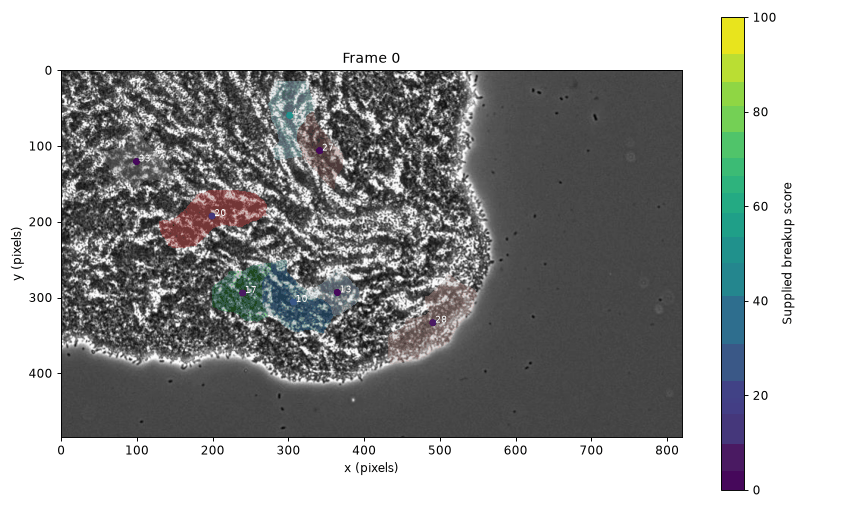

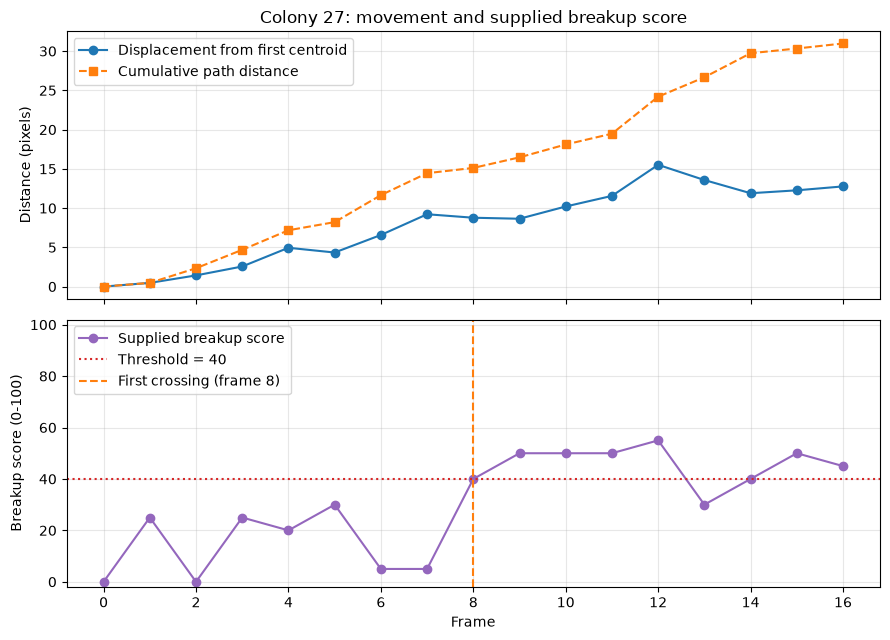

In [9]:
def save_trajectory_gif(images, measurements, output_path):
    frames = []
    for frame in range(len(images)):
        fig, ax = plt.subplots(figsize=(10, 6))
        ax.imshow(images[frame], cmap='gray')
        ax.imshow(np.ma.masked_equal(masks[frame], 0), cmap='tab20', alpha=0.35, interpolation='nearest')
        current = measurements[measurements.frame == frame]
        for ident, track in measurements.groupby('colony_id'):
            trail = track[track.frame <= frame].sort_values('frame')
            ax.plot(trail.centroid_x_px, trail.centroid_y_px, color='cyan', linewidth=0.8, alpha=0.65)
        valid = current.dropna(subset=['centroid_x_px', 'centroid_y_px'])
        points = ax.scatter(valid.centroid_x_px, valid.centroid_y_px, c=valid.breakup_score, cmap='viridis', vmin=0, vmax=100, s=25)
        for _, row in valid.iterrows():
            ax.text(row.centroid_x_px+3, row.centroid_y_px, str(int(row.colony_id)), color='white', fontsize=8)
        fig.colorbar(points, ax=ax, label='Supplied breakup score')
        ax.set(title=f'Frame {frame}', xlabel='x (pixels)', ylabel='y (pixels)')
        fig.tight_layout()
        buffer = io.BytesIO(); fig.savefig(buffer, format='png', dpi=85); plt.close(fig)
        buffer.seek(0); frames.append(Image.open(buffer).convert('RGB'))
    frames[0].save(output_path, save_all=True, append_images=frames[1:], duration=300, loop=0)

def display_trajectory_gif(images, measurements):
    local_gif = OUTPUT / 'trajectories.gif'
    save_trajectory_gif(images, measurements, local_gif)
    display(NotebookImage(data=local_gif.read_bytes(), format='gif'))

display_trajectory_gif(images, measurements)

focus_id = int(most_increase.colony_id)
track = measurements[measurements.colony_id == focus_id].sort_values('frame')
cross = summary.loc[summary.colony_id == focus_id, 'first_threshold_frame'].iloc[0]
fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True)
top.plot(track.frame, track.displacement_px, 'o-', label='Displacement from first centroid')
top.plot(track.frame, track.cumulative_distance_px, 's--', label='Cumulative path distance')
top.set(ylabel='Distance (pixels)', title=f'Colony {focus_id}: movement and supplied breakup score')
top.legend(); top.grid(alpha=0.3)
bottom.plot(track.frame, track.breakup_score, 'o-', color='tab:purple', label='Supplied breakup score')
bottom.axhline(THRESHOLD, color='tab:red', linestyle=':', label=f'Threshold = {THRESHOLD:g}')
if pd.notna(cross):
    bottom.axvline(int(cross), color='tab:orange', linestyle='--', label=f'First crossing (frame {int(cross)})')
bottom.set(xlabel='Frame', ylabel='Breakup score (0-100)', ylim=(-2, 102))
bottom.legend(loc='upper left'); bottom.grid(alpha=0.3)
fig.tight_layout(); plt.show()

## 9. Store results in this notebook and check
Numerical grading uses absolute tolerances: 0.05 pixels for centroids, 0.10 pixels for
distances, 0.01 score points for score changes, and exact frame numbers for crossings.
Partial credit is the fraction of correct required entries; missing or nonfinite answers
fail finite reference entries. Duplicate colony/frame rows are invalid. Keep at least 3 decimals
in your calculations. Use NaN for missing observations.

70 automatic points: centroids 20, movement 30, breakup changes/crossings 20.
30 review points: loading/overlay/complete outputs 10, visualization 10, interpretation 10.


In [10]:
assert measurements is not None and summary is not None
assert not measurements.duplicated(['colony_id', 'frame']).any()
assert not summary.duplicated(['colony_id']).any()
expected = pd.MultiIndex.from_product([colony_ids, range(len(masks))], names=['colony_id', 'frame'])
actual = pd.MultiIndex.from_frame(measurements[['colony_id', 'frame']])
assert set(actual) == set(expected), 'Include every required colony/frame pair'
assert set(summary.colony_id) == set(colony_ids)
# Show complete tables in expandable sections, with full numeric results embedded for grading.
import json
payload = {'biofilm_challenge_version': 1,
    'measurements': json.loads(measurements.to_json(orient='records', double_precision=12)),
    'summary': json.loads(summary.to_json(orient='records', double_precision=12))}
html = ('<details><summary>Frame-by-frame measurements</summary>' + measurements.to_html(index=False) + '</details>'
        + '<details><summary>Colony summaries</summary>' + summary.to_html(index=False) + '</details>')
display({'application/json': payload, 'text/html': html,
         'text/plain': 'Complete challenge results: frame measurements and colony summaries'}, raw=True)
print('Results are now embedded. Save this notebook with outputs retained before submitting.')


colony_id,frame,centroid_x_px,centroid_y_px,displacement_px,step_distance_px,cumulative_distance_px,breakup_score,breakup_change
10,0,306.528642,305.864568,0.000000,0.000000,0.000000,25.0,0.0
10,1,306.562030,308.085472,2.221155,2.221155,2.221155,20.0,-5.0
10,2,306.089985,307.379317,1.576986,0.849400,3.070556,20.0,-5.0
10,3,305.715588,306.419784,0.984542,1.029989,4.100545,20.0,-5.0
10,4,306.434558,304.853055,1.015878,1.723820,5.824365,25.0,0.0
10,5,307.451053,302.823686,3.177704,2.269714,8.094079,25.0,0.0
10,6,308.748375,303.217888,3.454291,1.355890,9.449969,25.0,0.0
10,7,309.607819,303.184361,4.082259,0.860098,10.310068,25.0,0.0
10,8,309.488147,305.694384,2.964395,2.512873,12.822941,15.0,-10.0
10,9,309.781526,306.131517,3.263820,0.526457,13.349398,15.0,-10.0


Results are now embedded. Save this notebook with outputs retained before submitting.


## 10. Your interpretation (100–150 words)
Name the colony with greatest final displacement and the colony with greatest score increase.
Discuss one example using your graph and images. Explain one limitation: for example,
centroid shifts can reflect shape changes, or a supplied breakup score does not prove cell release.

### Interpretation

Colony 33 moved farthest from its start (final displacement 37.18 px). Its path was fairly direct: 42.89 px of total distance, with displacement rising steadily from frame 3 in the animation. Colony 27 had the largest increase in breakup score (+45). In the two-panel figure it first reaches the threshold of 40 at frame 8 and mostly stays above it. Its cumulative distance (30.97 px) is much larger than its displacement (12.76 px), so the centroid wanders instead of drifting in one direction. Colony 41 already met the threshold at frame 0.

Limitation: a centroid follows the shape of a territory, not the cells inside it. Colony 28's centroid jumps 24.96 px between frames 0 and 1 while its mask shrinks from 6,897 to 4,424 pixels, which is a change in shape rather than real movement. Also, a high breakup score does not prove that cells were released.